In [1]:

# =========================================================
#                  IMPORT LIBRARIES
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import warnings
warnings.filterwarnings("ignore")

sns.set_palette("coolwarm")

In [2]:
# =========================================================
#                     LOAD DATASET
# =========================================================

df = pd.read_csv("fake_internship_detection_dataset.csv")

In [3]:
print("Dataset Shape :", df.shape)

print("\nColumns:\n")

print(df.columns)

df.head()


Dataset Shape : (1000000, 33)

Columns:

Index(['posting_date', 'internship_title', 'employment_type', 'work_mode',
       'industry', 'location', 'company_name', 'company_size', 'company_age',
       'linkedin_presence', 'website_available', 'domain_age_months',
       'verification_status', 'stipend', 'unrealistic_salary_flag',
       'payment_required', 'registration_fee', 'job_description_length',
       'grammatical_errors', 'vague_description_score', 'urgency_score',
       'keyword_spam_score', 'fake_certificate_offer',
       'recruiter_experience_years', 'recruiter_email_type',
       'suspicious_email_domain', 'recruiter_response_time_hours',
       'social_media_presence', 'emotional_manipulation_score',
       'phishing_language_score', 'trust_signal_score', 'fraud_score',
       'is_fake_posting'],
      dtype='object')


,posting_date,internship_title,employment_type,work_mode,industry,location,company_name,company_size,company_age,linkedin_presence,...,recruiter_experience_years,recruiter_email_type,suspicious_email_domain,recruiter_response_time_hours,social_media_presence,emotional_manipulation_score,phishing_language_score,trust_signal_score,fraud_score,is_fake_posting
0,2026-09-10,ML Engineer,Internship,Remote,Marketing,Berlin,"Russell, Medina and Evans",Startup,23.0,1,...,0.3,Free,1,17.6,1,12,28,48.4,51.8,1
1,2020-05-10,UI/UX Designer,Contract,Onsite,Marketing,Bangalore,Hays-White,Startup,12.0,0,...,5.1,Free,1,30.2,1,9,27,47.6,75.3,1
2,2021-07-18,UI/UX Designer,Internship,Hybrid,Gaming,Toronto,"Obrien, Gonzalez and Harris",Small,10.0,1,...,6.0,Free,1,12.5,0,26,18,98.8,0.0,0
3,2021-02-04,UI/UX Designer,Part-Time,Remote,AI,Berlin,"Martinez, Odonnell and Davidson",Enterprise,33.0,1,...,3.8,Corporate,0,24.6,1,20,0,72.2,11.0,0
4,2020-12-31,AI Research Intern,Internship,Onsite,EdTech,Toronto,Garcia-Owens,Small,14.0,0,...,7.0,Free,1,30.3,0,16,50,34.4,56.0,1


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 33 columns):
 #   Column                         Non-Null Count    Dtype  
---  ------                         --------------    -----  
 0   posting_date                   1000000 non-null  object 
 1   internship_title               1000000 non-null  object 
 2   employment_type                1000000 non-null  object 
 3   work_mode                      1000000 non-null  object 
 4   industry                       1000000 non-null  object 
 5   location                       1000000 non-null  object 
 6   company_name                   1000000 non-null  object 
 7   company_size                   1000000 non-null  object 
 8   company_age                    990000 non-null   float64
 9   linkedin_presence              1000000 non-null  int64  
 10  website_available              1000000 non-null  int64  
 11  domain_age_months              1000000 non-null  int64  
 12  verification_st

In [7]:
df.describe()

,company_age,linkedin_presence,website_available,domain_age_months,verification_status,stipend,unrealistic_salary_flag,payment_required,registration_fee,job_description_length,...,fake_certificate_offer,recruiter_experience_years,suspicious_email_domain,recruiter_response_time_hours,social_media_presence,emotional_manipulation_score,phishing_language_score,trust_signal_score,fraud_score,is_fake_posting
count,990000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,990000.000000,1000000.0,1000000.000000,1000000.000000,1000000.000000,...,1000000.00000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,990000.000000,1000000.000000,1000000.000000
mean,20.000174,0.800764,0.849597,239.541209,0.699713,35066.198206,0.0,0.099905,252.083069,1799.538324,...,0.07983,5.052660,0.250567,18.180467,0.749800,25.563839,20.749288,56.555847,34.012258,0.221958
std,11.252082,0.399426,0.357466,135.737891,0.458383,14830.059509,0.0,0.299873,881.467489,598.563156,...,0.27103,2.871692,0.433340,9.611051,0.433128,18.129998,15.884219,16.362310,21.371783,0.415563
min,1.000000,0.000000,0.000000,1.000000,0.000000,2000.000000,0.0,0.000000,0.000000,100.000000,...,0.00000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,10.000000,1.000000,1.000000,123.000000,0.000000,24841.000000,0.0,0.000000,0.000000,1395.000000,...,0.00000,3.000000,0.000000,11.200000,0.000000,11.000000,7.000000,45.600000,18.100000,0.000000
50%,20.000000,1.000000,1.000000,240.000000,1.000000,34984.000000,0.0,0.000000,0.000000,1799.000000,...,0.00000,5.000000,0.000000,18.000000,1.000000,24.000000,19.000000,56.900000,32.300000,0.000000
75%,30.000000,1.000000,1.000000,356.000000,1.000000,45124.000000,0.0,0.000000,0.000000,2203.000000,...,0.00000,7.000000,1.000000,24.800000,1.000000,38.000000,32.000000,67.900000,47.800000,0.000000
max,39.000000,1.000000,1.000000,500.000000,1.000000,110428.000000,0.0,1.000000,4999.000000,5000.000000,...,1.00000,19.600000,1.000000,63.900000,1.000000,100.000000,100.000000,100.000000,100.000000,1.000000


In [4]:
# =========================================================
#                  MISSING VALUES
# =========================================================

df.isnull().sum()



posting_date                         0
internship_title                     0
employment_type                      0
work_mode                            0
industry                             0
location                             0
company_name                         0
company_size                         0
company_age                      10000
linkedin_presence                    0
website_available                    0
domain_age_months                    0
verification_status                  0
stipend                          10000
unrealistic_salary_flag              0
payment_required                     0
registration_fee                     0
job_description_length               0
grammatical_errors                   0
vague_description_score              0
urgency_score                        0
keyword_spam_score                   0
fake_certificate_offer               0
recruiter_experience_years           0
recruiter_email_type                 0
suspicious_email_domain  

In [5]:
# =========================================================
#                HANDLE MISSING VALUES
# =========================================================

for col in df.select_dtypes(include=np.number).columns:

    df[col].fillna(df[col].median(),inplace=True)

for col in df.select_dtypes(include="object").columns:

    df[col].fillna(df[col].mode()[0], inplace=True)


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
# =========================================================
#                EXPORT CLEANED DATASET
# =========================================================
df.to_csv("cleaned_internship_scam_dataset.csv", index=False)

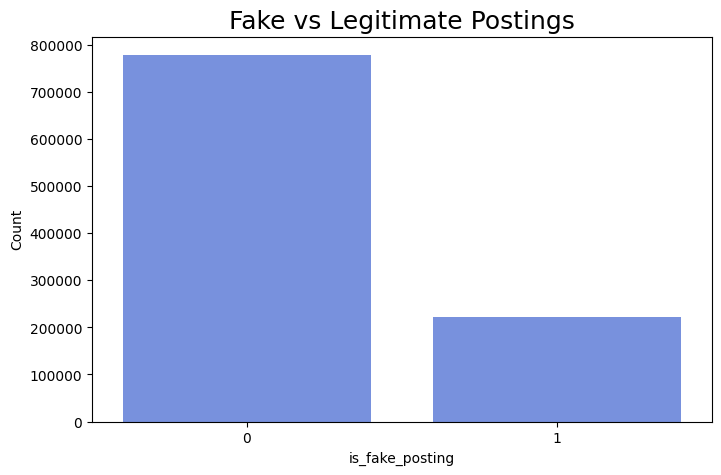

In [9]:
# =========================================================
#                  TARGET DISTRIBUTION
# =========================================================

plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="is_fake_posting"
)

plt.title(
    "Fake vs Legitimate Postings",
    fontsize=18
)

plt.xlabel("is_fake_posting")

plt.ylabel("Count")

plt.show()

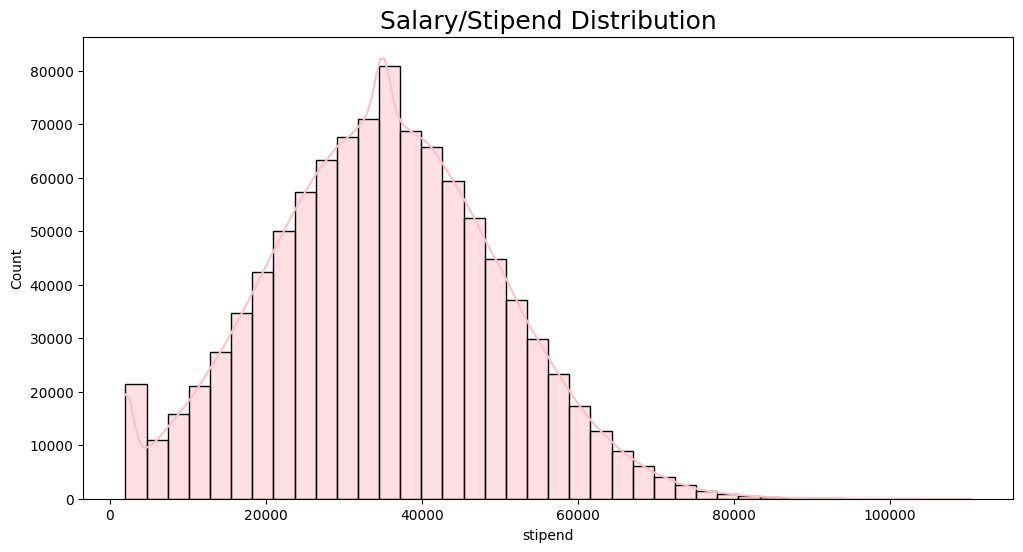

In [10]:
# =========================================================
#                 SALARY DISTRIBUTION
# =========================================================

plt.figure(figsize=(12,6))

sns.histplot(
    df["stipend"],
    bins=40,
    kde=True,
    color="pink"
)

plt.title(
    "Salary/Stipend Distribution",
    fontsize=18
)

plt.show()


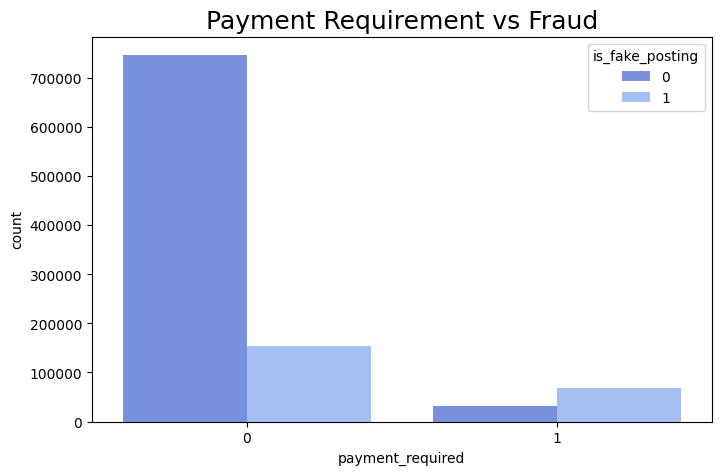

In [11]:
# =========================================================
#              PAYMENT REQUIRED ANALYSIS
# =========================================================

plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="payment_required",
    hue="is_fake_posting"
)

plt.title(
    "Payment Requirement vs Fraud",
    fontsize=18
)

plt.show()

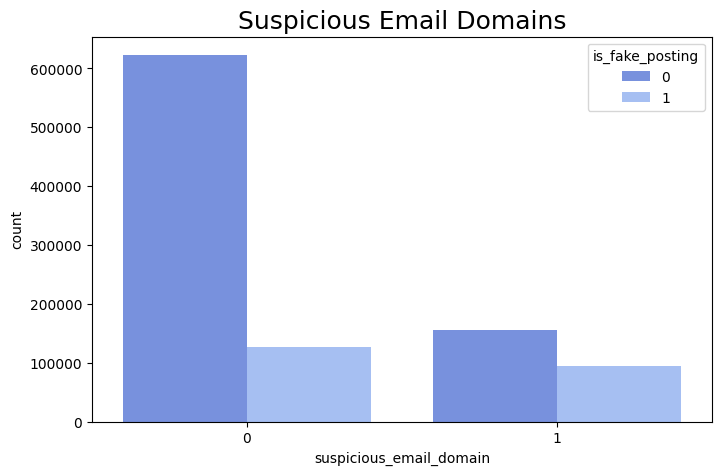

In [12]:
# =========================================================
#               SUSPICIOUS EMAIL ANALYSIS
# =========================================================

plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="suspicious_email_domain",
    hue="is_fake_posting"
)

plt.title(
    "Suspicious Email Domains",
    fontsize=18
)

plt.show()

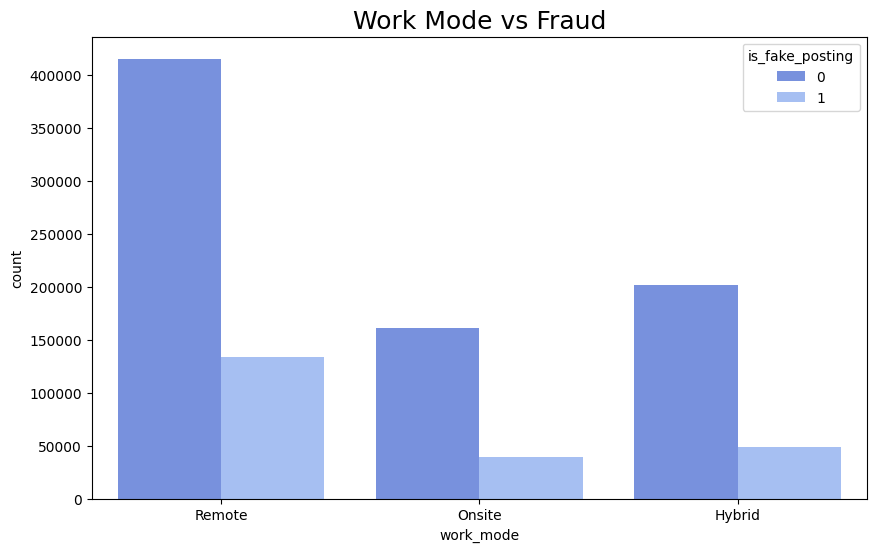

In [13]:

# =========================================================
#                    WORK MODE ANALYSIS
# =========================================================

plt.figure(figsize=(10,6))

sns.countplot(
    data=df,
    x="work_mode",
    hue="is_fake_posting"
)

plt.title(
    "Work Mode vs Fraud",
    fontsize=18
)

plt.show()


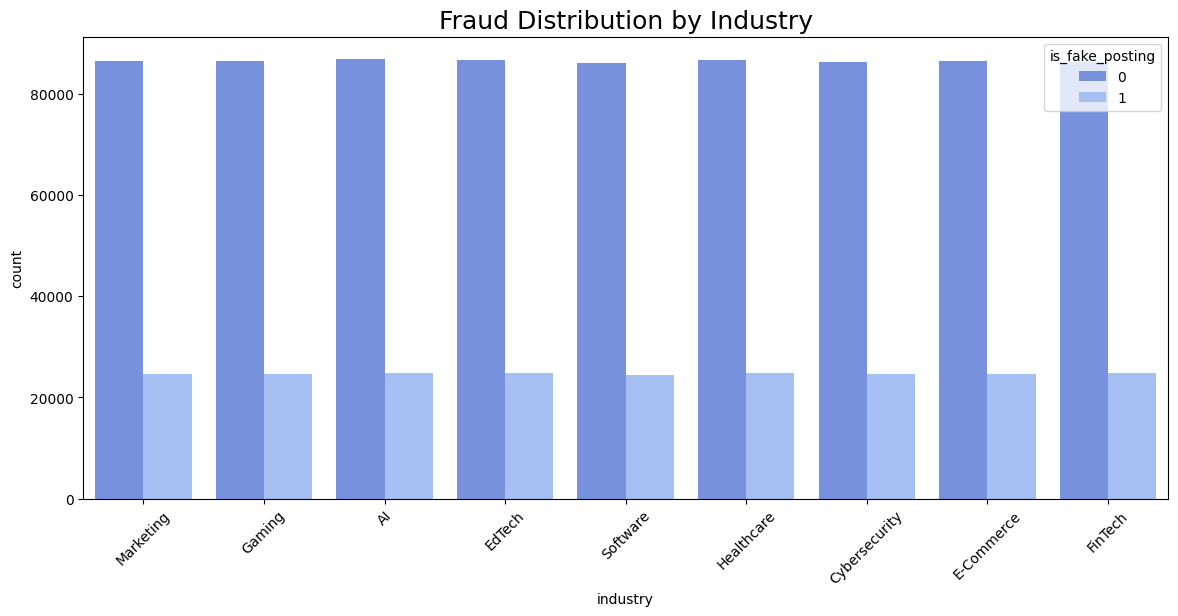

In [14]:
# =========================================================
#                INDUSTRY FRAUD ANALYSIS
# =========================================================

plt.figure(figsize=(14,6))

sns.countplot(
    data=df,
    x="industry",
    hue="is_fake_posting"
)

plt.xticks(rotation=45)

plt.title(
    "Fraud Distribution by Industry",
    fontsize=18
)

plt.show()

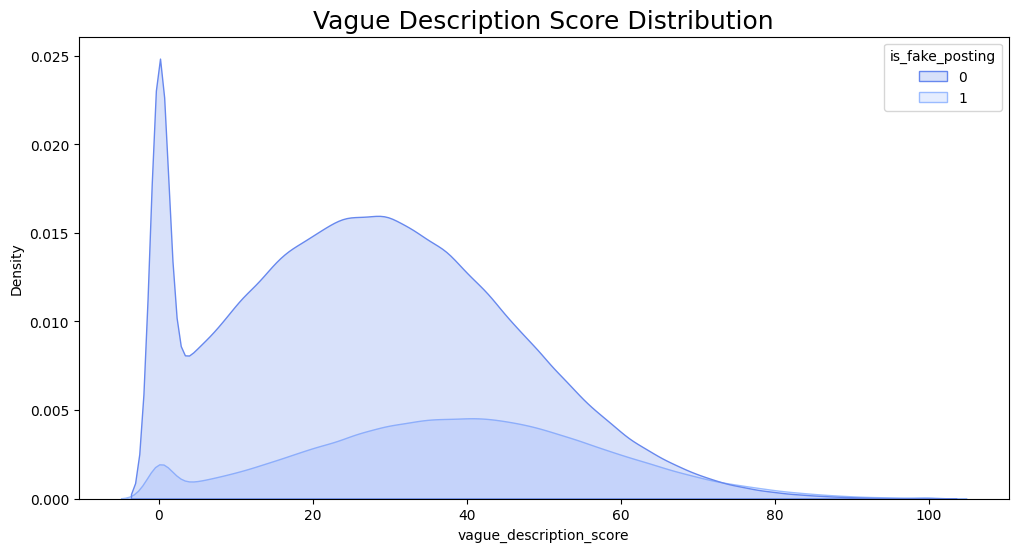

In [15]:
# =========================================================
#              VAGUE DESCRIPTION ANALYSIS
# =========================================================

plt.figure(figsize=(12,6))

sns.kdeplot(
    data=df,
    x="vague_description_score",
    hue="is_fake_posting",
    fill=True
)

plt.title(
    "Vague Description Score Distribution",
    fontsize=18
)

plt.show()

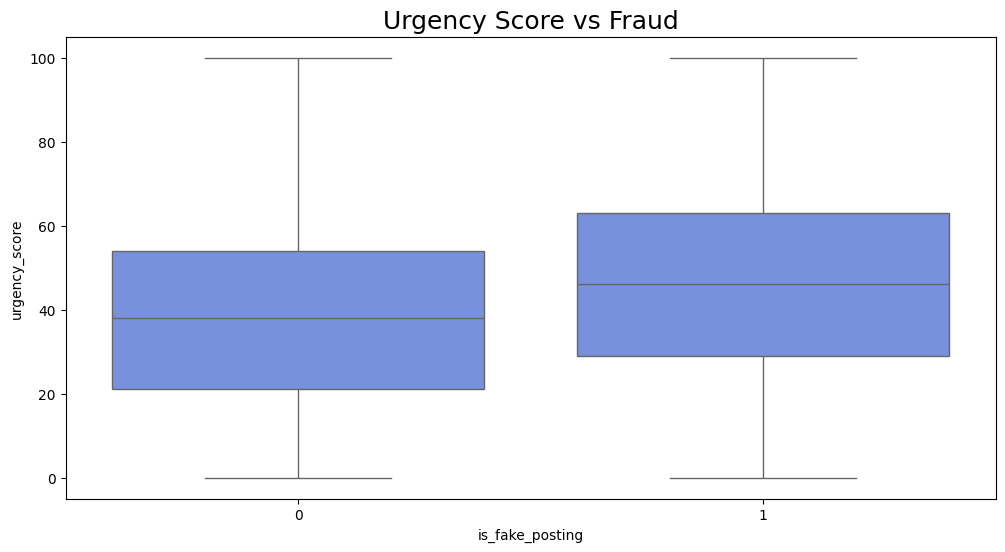

In [16]:
# =========================================================
#              URGENCY SCORE ANALYSIS
# =========================================================

plt.figure(figsize=(12,6))

sns.boxplot(
    data=df,
    x="is_fake_posting",
    y="urgency_score"
)

plt.title(
    "Urgency Score vs Fraud",
    fontsize=18
)

plt.show()

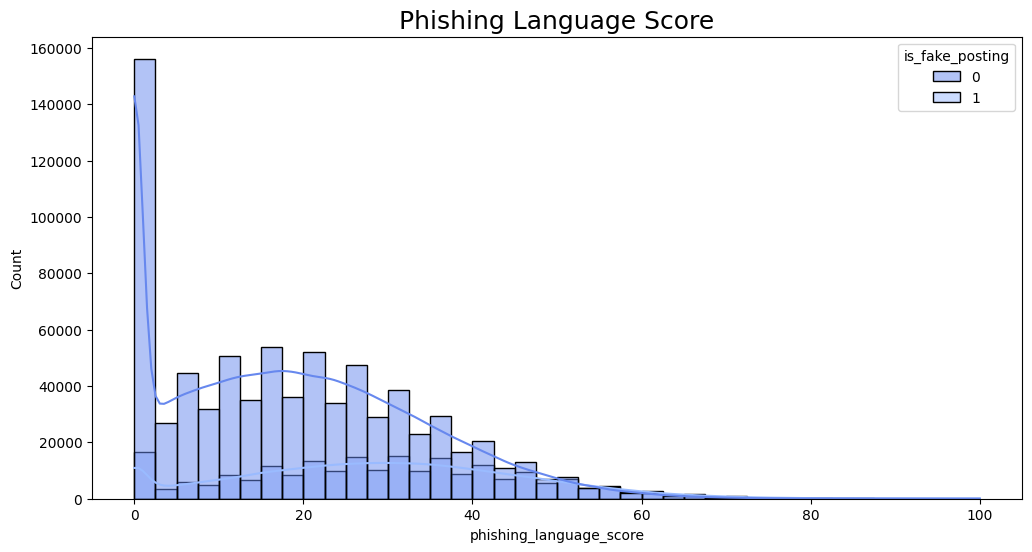

In [17]:
# =========================================================
#              PHISHING LANGUAGE ANALYSIS
# =========================================================

plt.figure(figsize=(12,6))

sns.histplot(
    data=df,
    x="phishing_language_score",
    hue="is_fake_posting",
    bins=40,
    kde=True
)

plt.title(
    "Phishing Language Score",
    fontsize=18
)

plt.show()

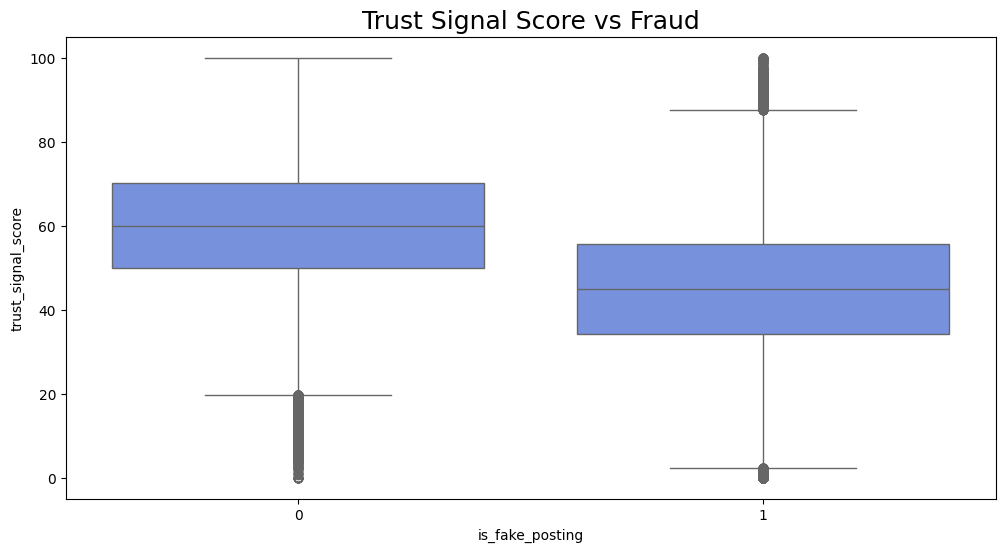

In [18]:
# =========================================================
#                TRUST SIGNAL ANALYSIS
# =========================================================

plt.figure(figsize=(12,6))

sns.boxplot(
    data=df,
    x="is_fake_posting",
    y="trust_signal_score"
)

plt.title(
    "Trust Signal Score vs Fraud",
    fontsize=18
)

plt.show()

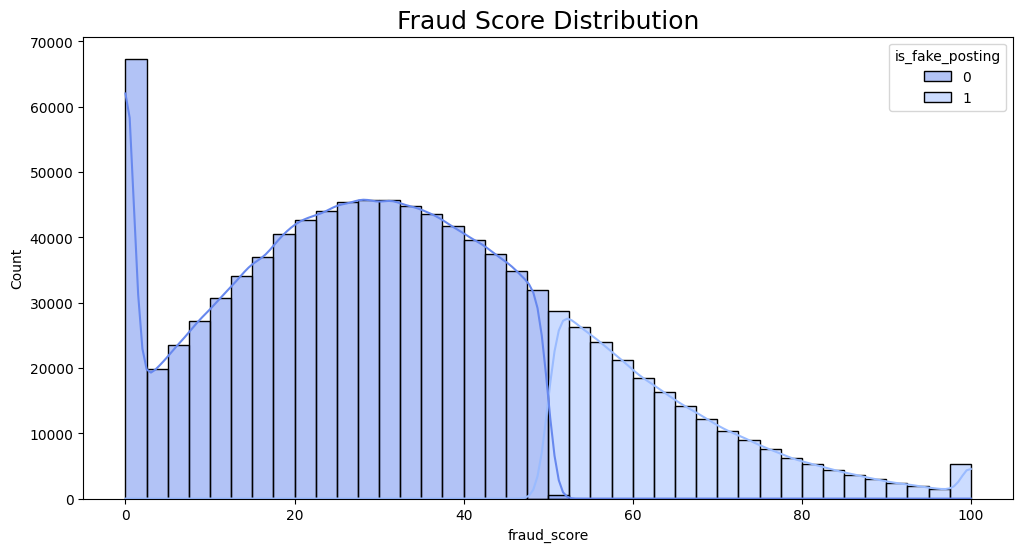

In [19]:

# =========================================================
#               FRAUD SCORE DISTRIBUTION
# =========================================================

plt.figure(figsize=(12,6))

sns.histplot(
    data=df,
    x="fraud_score",
    hue="is_fake_posting",
    bins=40,
    kde=True
)

plt.title(
    "Fraud Score Distribution",
    fontsize=18
)

plt.show()

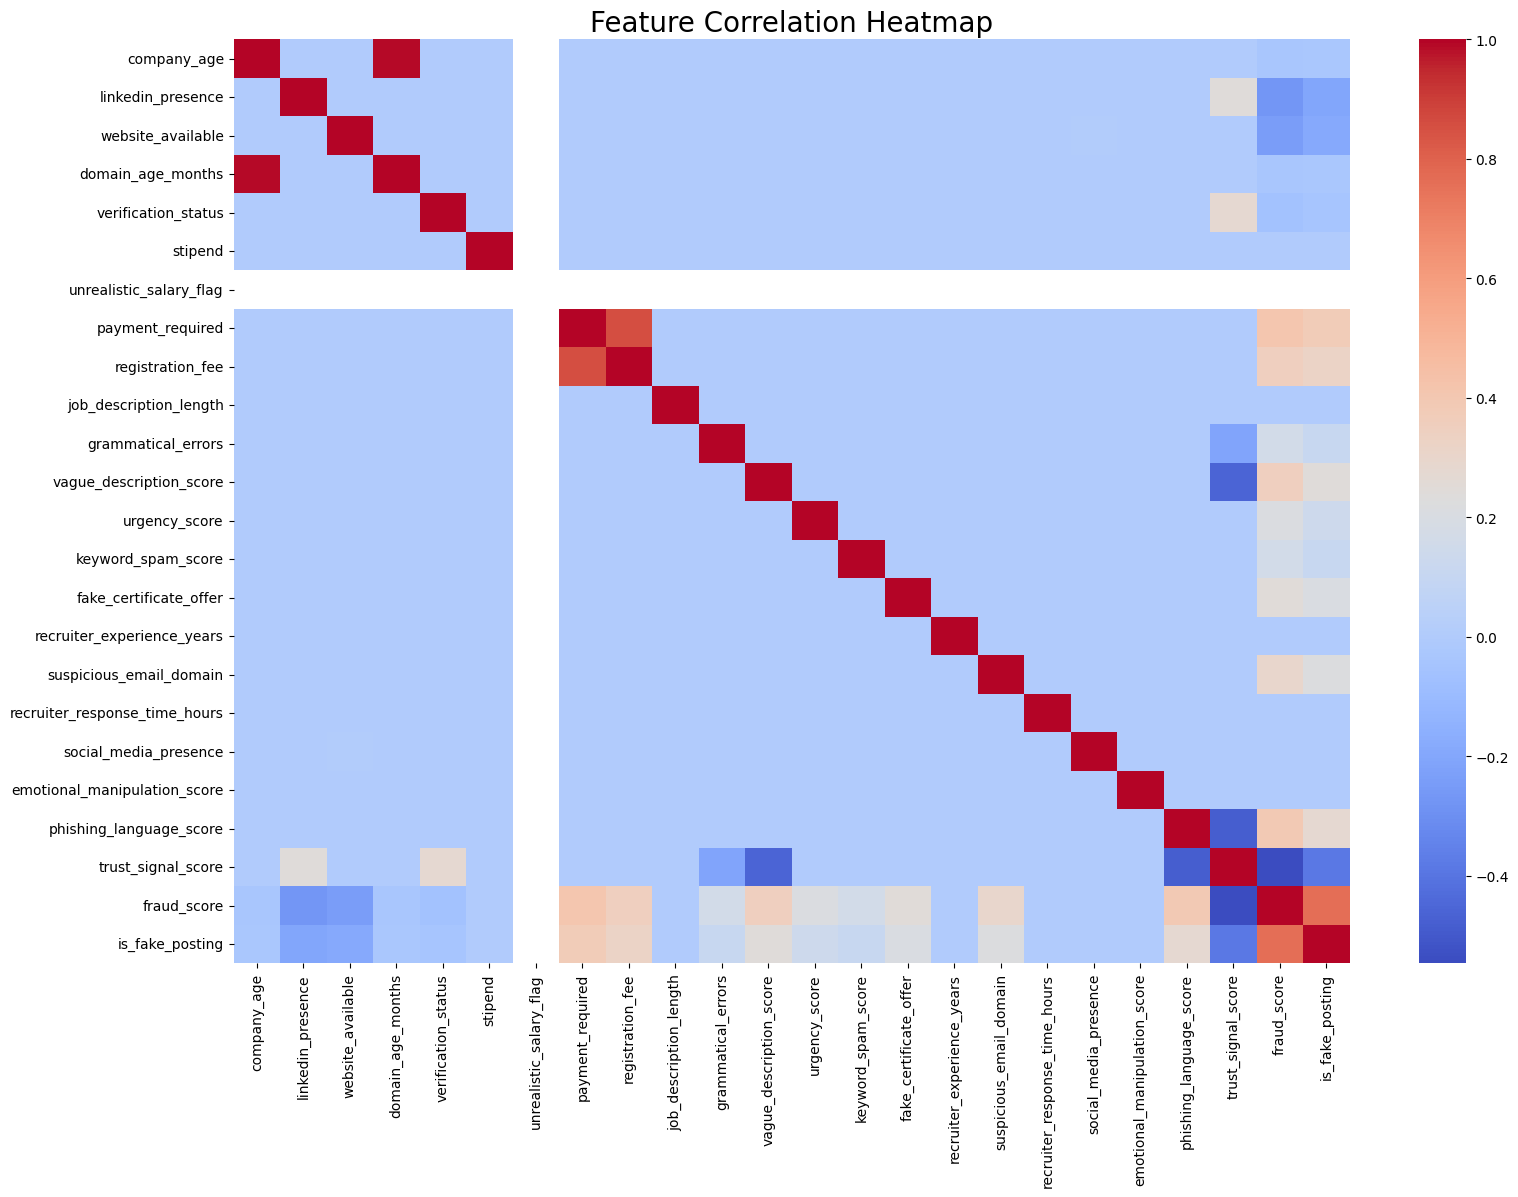

In [20]:
# =========================================================
#                  CORRELATION HEATMAP
# =========================================================

plt.figure(figsize=(18,12))

corr = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    corr,
    cmap="coolwarm",
    annot=False
)

plt.title(
    "Feature Correlation Heatmap",
    fontsize=20
)

plt.show()


In [21]:
# =========================================================
#                 FEATURE ENGINEERING
# =========================================================

df["risk_index"] = (

    df["payment_required"] * 30

    + df["phishing_language_score"] * 0.5

    + df["urgency_score"] * 0.3

    + df["keyword_spam_score"] * 0.3

    - df["trust_signal_score"] * 0.4
)

df["company_trust_index"] = (

    df["linkedin_presence"] * 30

    + df["verification_status"] * 30

    + df["website_available"] * 20
)

In [22]:
# =========================================================
#                   LABEL ENCODING
# =========================================================

encoder = LabelEncoder()

for col in df.select_dtypes(include="object").columns:

    df[col] = encoder.fit_transform(df[col])

In [23]:
# =========================================================
#                 FEATURES & TARGET
# =========================================================

X = df.drop( "is_fake_posting",  axis=1
)
y = df["is_fake_posting"]


In [24]:
# =========================================================
#                    TRAIN TEST SPLIT
# =========================================================

X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42 )

In [25]:
# =========================================================
#                       XGBOOST MODEL
# =========================================================

from xgboost import XGBClassifier

model = XGBClassifier(

    n_estimators=200,

    max_depth=8,

    learning_rate=0.05,

    subsample=0.8,

    colsample_bytree=0.8,

    random_state=42,

    eval_metric="logloss",

    n_jobs=-1
)

# =========================================================
#                     TRAIN MODEL
# =========================================================

model.fit(
    X_train,
    y_train
)

# =========================================================
#                    PREDICTIONS
# =========================================================

y_pred = model.predict(X_test)

# =========================================================
#                MODEL EVALUATION
# =========================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Accuracy :", accuracy)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred
    )
)



Accuracy : 0.99934

Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    155728
           1       1.00      1.00      1.00     44272

    accuracy                           1.00    200000
   macro avg       1.00      1.00      1.00    200000
weighted avg       1.00      1.00      1.00    200000



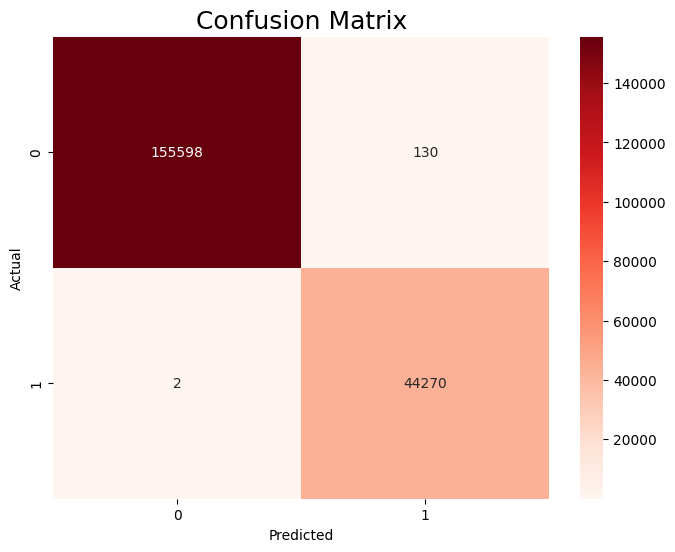

In [26]:
# =========================================================
#                 CONFUSION MATRIX
# =========================================================

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Reds"
)

plt.title(
    "Confusion Matrix",
    fontsize=18
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()



In [27]:

# =========================================================
#                  FEATURE IMPORTANCE
# =========================================================

importance = pd.DataFrame({

    "Feature": X.columns,

    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)


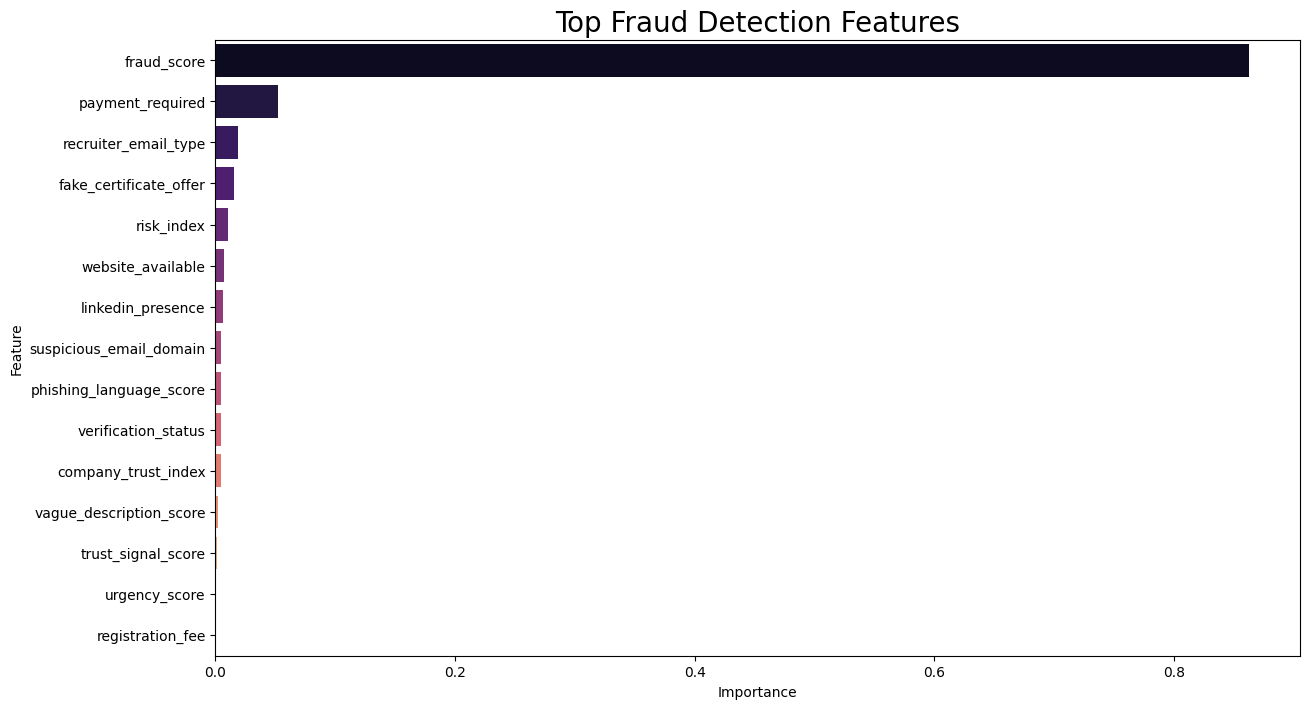

In [28]:
# =========================================================
#            TOP IMPORTANT FEATURES
# =========================================================

plt.figure(figsize=(14,8))

sns.barplot(

    data=importance.head(15),

    x="Importance",

    y="Feature",

    palette="magma"
)

plt.title(
    "Top Fraud Detection Features",
    fontsize=20
)

plt.show()